# IIR Filter -Chebyshev Filters

<font color="blue">Note: In order to run this Jupyter Notebook you must create a file named `digital_filters.py` inside the folder containing this Notebook with the following functions `filter_frequency_response` and `zeros_poles_gain` which were developed previously.</font> 

Chebyshev filters are used to separate one band of frequencies from another. Although they cannot match the performance of the windowed-sinc filter, they are more than adequate for many applications. The primary attribute of Chebyshev filters is their speed, typically more than an order of magnitude faster than the windowed-sinc. This is because they are carried out by recursion rather than convolution. The design of these filters is based on the z-transform.

## The Chebyshev and Butterworth Responses
The Chebyshev response is a mathematical strategy for achieving a faster roll-off by allowing ripple in the frequency response. Analog and digital filters that use this approach are called Chebyshev filters. These filters are named from their use of the Chebyshev polynomials, developed by the Russian mathematician Pafnuti Chebyshev (1821-1894).

The Figure shows the frequency response of low-pass Chebyshev filters with passband ripples of: 0%, 0.5% and 20%. As the ripple increases (bad), the roll-off becomes sharper (good). The Chebyshev response is an optimal trade-off between these two parameters. When the ripple is set to 0%, the filter is called a maximally flat or Butterworth filter (after S. Butterworth, a British engineer who described this response in 1930). A ripple of 0.5% is a often good choice for digital filters. This matches the typical precision and accuracy of the analog electronics that the signal has passed through.

![Chebyshev Roll Off](Images/Chebyshev_Roll_Off.gif)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

from digital_filters import filter_frequency_response, zeros_poles_gain
from aux_plots import plot_zeros_poles, plot_frequency_response
from scipy.signal import cheby1
from scipy.signal import lfilter

## Designing the Filter
You must select four parameters to design a Chebyshev filter: 
1. A high-pass or low-pass response.
2. The cutoff frequency.
3. The allowed ripple in the passband.
4. The number of poles. 

We will design a 6th order low pass Chebyshev filter with a cutoff frequency of 16Hz for a signal that has been sampled at 64Hz. The allowed ripple for this filter is 0.1 dB.

In [2]:
# Set a sampling frequency variable fs to 64 Hz
### BEGIN SOLUTION
fs = 64  # Hz
### END SOLUTION

# Desired filter parameters
# Set an order variable to 6
### BEGIN SOLUTION
order = 6
### END SOLUTION

# Set a ripple variable to 0.1 dB
### BEGIN SOLUTION
ripple = 0.1 
### END SOLUTION

# Set a fcut variable to 16 Hz
### BEGIN SOLUTION
fcut = 16 
### END SOLUTION

# The scipy.signal.cheby1 function uses a normalized frequency argument variable wn
# Find the normalized wn value
### BEGIN SOLUTION
wn = fcut / (0.5*fs)
### END SOLUTION

# Use the scipy.signal.cheby1 function to create a lowpass filter with the
# order, ripple, wn variables.
# Other btype arguments can be 'lowpass', 'highpass', 'bandpass' or 'bandstop'
### BEGIN SOLUTION
a, b = cheby1(order, ripple, wn, btype='lowpass')
### END SOLUTION

In [3]:
with open('cheby1.pkl', 'rb') as file:
    a_pkl,b_pkl = pickle.load(file)
    
assert np.isclose(a_pkl, a).all()
assert np.isclose(b_pkl, b).all()

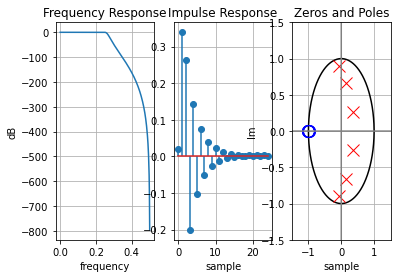

In [4]:
# We need to put our coefficients in our programming style.
c = np.flip(a)
d = np.flip(b)
w = np.arange(0, np.pi, 0.01)

H_w = filter_frequency_response(c, d, w)
idft = np.fft.ifft(H_w)
z, p, g = zeros_poles_gain(c, d)

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1, 3, 1)
plt.plot(w/(2*max(w)), 20*np.log(np.absolute(H_w)))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

plt.subplot(1, 3, 2)
plt.stem(np.real(idft[0:25]), use_line_collection=True)
plt.title('Impulse Response')
plt.xlabel('sample')
plt.grid('on')

plot_zeros_poles(z, p)
plt.title('Zeros and Poles')
plt.xlabel('sample');

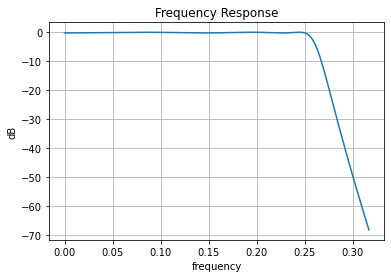

In [5]:
plt.plot(w[0:200]/(2*max(w)), 20*np.log(np.absolute(H_w[0:200])))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

## Using the Filter
We will use the designed filter by implementing the difference equation

$$ y[n] = a_0 x[n] + a_1 x[n-1] + a_2 x[n-2] + \cdot \cdot \cdot + b_1 y[n-1] + b_2 y[n-2] + \cdot \cdot \cdot $$ 

as a **Direct II Transposed Structure**.

The following Figure shows an example of a direct II transpose structure.

![Direct II Transposed Structure](Images/Transposed_Direct_Form_II.png)

As it can bee seen in the Figure, a state variable $s[n]$ is introduced. 

The following code shows the pseudo code implementation of the direct II transpose structure.

``` python
     y[n] = a[0] * x[n]               + s[0][n-1]
  s[0][n] = a[1] * x[n] - b[1] * y[n] + s[1][n-1]
  s[1][n] = a[2] * x[n] - b[2] * y[n] + s[2][n-1]
...
s[N-2][n] = a[N-1]*x[n] - b[N-1]*y[n] + s[N-1][n-1]
s[N-1][n] = a[N] * x[n] - b[N] * y[n]

```

Now you need to create a function named `filter_dtype_ii` and implement the direct II transpose structure. This function takes as input an array `a` of numerator coefficients, an array `b` of denominator coefficients, and a signal `x`.

In [6]:
def filter_dtype_ii(a, b, x):
    """ 
    Direct II Transposed Structure implementation of digital filter.
  
    Parameters: 
    a (numpy array): Array of numerator filter coefficients.
    b (numpy array): Array of denominator filter coefficients.
    x (numpy array): Array of signal of interest.
  
    Returns: 
    numpy array: Returns filter response.
  
    """
    ### BEGIN SOLUTION
    N = x.shape[0]
    order = a.shape[0] - 1
    
    y = np.zeros(N)
    s = np.zeros(order)

    for k in range(N):
        temp_1 = a*x[k]

        y[k] = temp_1[0] + s[0]
        temp_2 = b[1:]*y[k]

        s = temp_1[1:] - temp_2 + np.append(s[1:],0)
    return y
    ### END SOLUTION

In [7]:
np.random.seed(42)
x = np.random.random(100)

assert np.allclose(filter_dtype_ii(a, b, x), lfilter(a, b, x), atol=0.01)

### Generating a signal for testing the filter
After you successfully created the Chebyshev filter, it is time to test it. For this purpose, we will create a dummy signal sampled at 64Hz that has two frequency components of 20 and 16Hz. Since our filter is a low pass one with a cutoff frequency of 16Hz, we should be able to get rid of the 20Hz component.

In [8]:
# Set a sampling frequency variable fs to 64 Hz
### BEGIN SOLUTION
fs = 64
### END SOLUTION

# Set two frequency components. One named fc1 to 20 Hz and the other fc2 to 16 Hz.
### BEGIN SOLUTION
fc1 = 20
fc2 = 16
### END SOLUTION

# Set a variable t with a range of values between 0 (inclusive) and 2 (exclusive)
# Separate each sample by 1/fs
### BEGIN SOLUTION
t = np.arange(0,2,1/fs)
### END SOLUTION

# Create two sine signals.
# Assign to x1 a sine signal with frequency fc1 and time t
# Assign to x2 a sine signal with frequency fc2 and time t
### BEGIN SOLUTION
x1 = np.sin(2*np.pi*fc1*t)
x2 = np.sin(2*np.pi*fc2*t)
### END SOLUTION

# Add both sine signals and assign it to x
### BEGIN SOLUTION
x = x1 + x2
### END SOLUTION

# Fourier calculation
dft = np.fft.fft2(x.reshape(-1,1))
X = np.abs(dft)
f = np.linspace(0, 1, X.shape[0])*2*fs

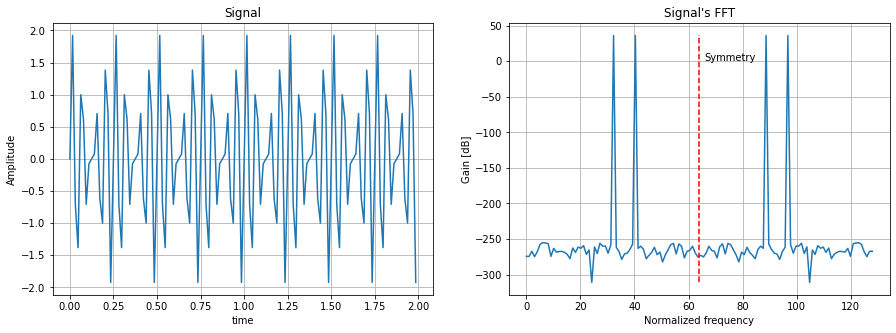

In [9]:
with open('signal.pkl', 'rb') as file:
    x_pkl, x1_pkl, x2_pkl = pickle.load(file)
    
assert np.isclose(x1_pkl, x1).all()
assert np.isclose(x2_pkl, x2).all()
assert np.isclose(x_pkl, x).all()

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1,2,1)
plt.plot(t,x)
plt.title('Signal')
plt.xlabel('time')
plt.ylabel('Amplitude')
plt.grid('on')

plt.subplot(1,2,2)
plot_frequency_response(X, f, title='Signal\'s FFT')

delta = 2
plt.vlines(x=fs, ymin=20*np.log10(X.min()), ymax=20*np.log10(X.max()+delta), linestyle='--', color='red')
plt.text(fs+delta, 0, 'Symmetry')

plt.show()

To test our filter function`filter_dtype_ii` we can compare it's results against the `lfilter` provided by SciPy.

In [10]:
# Use your function filter_dtype with signal x as input and the 
# Chevyshev coefficients a and b as parameters.
### BEGIN SOLUTION
y_filter = filter_dtype_ii(a, b, x)
### END SOLUTION

# Scipy Implementation is used here for comparisson
y_scipy = lfilter(a, b, x)

# Fourier Transform of our filter implementation
dft_filter = np.fft.fft2(y_filter.reshape(-1,1))
Y_filter = np.abs(dft_filter)
F_filter = np.linspace(0, 1, Y_filter.shape[0])*2*fs

# Fourier Transform of SciPy implementation
dft_scipy = np.fft.fft2(y_scipy.reshape(-1,1))
Y_scipy = np.abs(dft_scipy)
F_scipy = np.linspace(0, 1, Y_scipy.shape[0])*2*fs

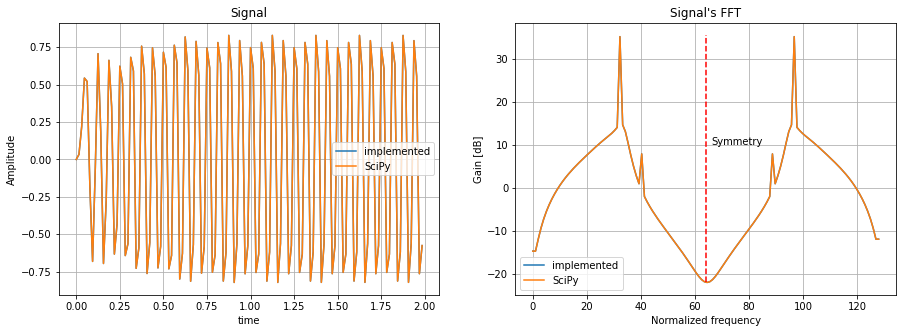

In [11]:
assert np.allclose(y_filter, y_scipy, atol=0.01)

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1,2,1)
plt.plot(t,y_filter, label='implemented')
plt.plot(t,y_scipy, label='SciPy')
plt.title('Signal')
plt.xlabel('time')
plt.ylabel('Amplitude')
plt.grid('on')
plt.legend();

plt.subplot(1,2,2)
plot_frequency_response(Y_filter, F_filter, title='Signal\'s FFT', label='implemented')
plot_frequency_response(Y_scipy, F_scipy, title='Signal\'s FFT', label='SciPy')
delta = 2
plt.vlines(x=fs, ymin=20*np.log10(Y_scipy.min()), ymax=20*np.log10(Y_scipy.max()+delta), linestyle='--', color='red')
plt.text(fs+delta, 10, 'Symmetry')
plt.legend();

#### Reference
* https://www.dspguide.com/ch20/2.htm 
* https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.cheby1.html 
* https://www.dsprelated.com/freebooks/filters/Four_Direct_Forms.html 
* https://www.dsprelated.com/freebooks/filters/Transposed_Direct_Forms.html